### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from typing import List

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import f, t, zscore
from sklearn.dummy import DummyRegressor
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### ფუნქციები

In [3]:
def apply_t_test(model: LinearRegression, X: pd.DataFrame, y: pd.Series) -> List[float]:
    """
    Perform a t-test to calculate p-values for the coefficients of a fitted linear regression model.

    Parameters:
    - model: A fitted linear regression model (e.g., from sklearn) with attributes `intercept_` and `coef_`.
    - X: pd.DataFrame, the design matrix used to fit the model.
    - y: pd.Series, the actual target values.

    Returns:
    - p_values: List of p-values corresponding to the intercept and coefficients.
    """
    # Ensure X is a NumPy array
    X = np.array(X)

    # Extract coefficients (intercept + slopes)
    beta_factors = np.concatenate(([model.intercept_], model.coef_))

    # Calculate predictions and residuals
    y_pred = model.predict(X)
    residuals = y - y_pred

    # Degrees of freedom
    n_samples, n_features = X.shape
    df = n_samples - (n_features + 1)  # +1 for the intercept

    # Residual variance
    residual_variance = np.sum(residuals**2) / df

    # Add intercept term
    X_with_intercept = np.column_stack([np.ones(n_samples), X])

    # Use pseudo-inverse to avoid singularity issues
    XTX_inv = np.linalg.pinv(X_with_intercept.T @ X_with_intercept)

    # Continue with variance calculation
    coef_variance = residual_variance * np.diag(XTX_inv)

    # Standard errors
    std_errors = np.sqrt(coef_variance)

    # Ensure standard errors are not zero for stability
    std_errors = np.where(std_errors == 0, 1e-10, std_errors)

    # t-values
    t_values = beta_factors / std_errors

    # Replace NaN or inf t-values with 0 for stability
    t_values = np.where(np.isnan(t_values) | np.isinf(t_values), 0, t_values)

    # p-values from two-tailed t-test
    p_values = [float(2 * (1 - t.cdf(np.abs(t_val), df=df))) if t_val != 0 else 1.0 for t_val in t_values]

    return p_values

In [4]:
def interpret_t_test(p_values: List[float], feature_names: np.ndarray) -> List[str]:
    """
    Interprets the T-Test p-values.

    Args:
        p_values (list): List of p-values from the T-Test.
        feature_names (list): List of feature names.

    Returns:
        list: Interpretation of the T-Test p-values.
    """
    t_test_interpretation = []
    for i, p_val in enumerate(p_values):
        if p_val < 0.05:
            t_test_interpretation.append(
                f"{feature_names[i]} is crucial for predicting the dependent variable (p-value={p_val:.4f}) < 0.05."
            )
        else:
            t_test_interpretation.append(
                f"{feature_names[i]} doesn't seem to add significant value (p-value={p_val:.4f}) ≥ 0.05."
            )
    return t_test_interpretation

In [5]:
def apply_f_test(model: LinearRegression, X: pd.DataFrame, y: pd.Series) -> float:
    """
    Perform an F-test to assess the overall significance of a fitted linear regression model.

    Parameters:
    - model: A fitted linear regression model (e.g., from sklearn) with a `predict` method.
    - X: pd.DataFrame, the design matrix used to fit the model.
    - y: pd.Series, the actual target values.

    Returns:
    - p_value_f: p-value corresponding to the F-statistic, indicating the overall model significance.
    """
    # Ensure X is a NumPy array
    X = np.array(X)

    # Calculate predictions
    y_pred = model.predict(X)

    # Calculate residuals
    residuals = y - y_pred

    # Sum of Squares for Regression (SSR)
    ssr = np.sum((y_pred - np.mean(y)) ** 2)

    # Sum of Squares for Error (SSE)
    sse = np.sum(residuals**2)

    # Degrees of freedom
    n_samples, n_features = X.shape
    df_regression = n_features  # Degrees of freedom for regression
    df_residual = n_samples - (n_features + 1)  # Degrees of freedom for residuals (+1 for intercept)

    # F-statistic
    if ssr == 0:
        f_statistic = 0
    elif sse == 0:
        f_statistic = np.inf
    else:
        f_statistic = (ssr / df_regression) / (sse / df_residual)

    # p-value from F-distribution
    if f_statistic != np.inf:
        p_value_f = 1 - f.cdf(f_statistic, df_regression, df_residual)
    else:
        p_value_f = 0

    return float(p_value_f)

In [6]:
def interpret_f_test(p_value_f: float) -> str:
    """
    Interprets the F-Test p-value.

    Args:
        p_value_f (float): The p-value from the F-Test.

    Returns:
        str: Interpretation of the F-Test p-value.
    """
    if p_value_f < 0.05:
        return f"The regression model is statistically significant (p-value={p_value_f:.4f} < 0.05), indicating that at least one predictor variable is significantly related to the target variable."
    else:
        return f"The regression model is not statistically significant (p-value={p_value_f:.4f} ≥ 0.05), indicating that the predictors are not related to the target variable."

In [7]:
def apply_grubbs_test(y: pd.Series, y_i: float, alpha: float = 0.05) -> tuple[bool, float, float]:
    """
    Perform Grubbs' Test for detecting a single outlier in the dataset.

    Parameters:
    - y: pd.Series, the dataset (1D array of numeric values).
    - y_i: float, datapoint to check if it is outlier.
    - alpha: float, significance level (default is 0.05).

    Returns:
    - is_outlier: Boolean, True if an outlier is detected, False otherwise.
    - grubbs_stat: Grubbs' statistic value.
    - critical_value: Critical value for Grubbs' test.
    """
    N = len(y)
    mean = np.mean(y)
    std_dev = np.std(y)

    # Test statistic
    grubbs_stat = np.max(np.abs(y_i - mean)) / std_dev

    # Critical value calculation based on the t-distribution and sample size
    t_value = t.ppf(1 - alpha / (2 * N), N - 2)
    critical_value = ((N - 1) / np.sqrt(N)) * (t_value / np.sqrt((N - 2) + t_value**2))

    # Determine if an outlier is present
    is_outlier = grubbs_stat > critical_value

    return bool(is_outlier), float(grubbs_stat), float(critical_value)

In [8]:
def interpret_grubbs_test(grubbs_test_outlier: bool, grubbs_stat: float, critical_value: float) -> str:
    """
    Interprets the result of the Grubbs test for outliers.

    Args:
        grubbs_test_outlier (bool): The result of the Grubbs test (True for outliers, False for no outliers).

    Returns:
        str: Interpretation of the Grubbs test result.
    """
    if grubbs_test_outlier:
        return f"Outliers were detected in the dataset (grubbs_stat={grubbs_stat:.4f} > critical_value={critical_value:.4f})."
    else:
        return f"No outliers were detected in the dataset (grubbs_stat={grubbs_stat:.4f} ≤ critical_value={critical_value:.4f})."

In [9]:
def apply_beta_factors(model: LinearRegression) -> np.ndarray:
    """
    Extract the beta factors (coefficients including the intercept) from a fitted linear regression model.

    Parameters:
    - model: A fitted linear regression model (e.g., from sklearn) with attributes `intercept_` and `coef_`.

    Returns:
    - beta_factors: np.array, array of coefficients including the intercept.
    """
    # Extract the intercept and coefficients
    beta_factors = np.concatenate(([model.intercept_], model.coef_))
    return beta_factors

In [10]:
def interpret_beta_factors(beta_factors: np.ndarray, feature_names: np.ndarray) -> list:
    """
    Interprets the Beta factors (coefficients) from the linear regression model.

    Args:
        beta_factors (list): List of beta factors (including intercept).
        feature_names (list): List of feature names.

    Returns:
        list: Interpretation of the Beta factors.
    """
    beta_factors_interpretation = {name: beta_factors[i] for i, name in enumerate(feature_names)}

    # Interpretation of beta factors
    beta_interpretation = [
        f"The coefficient for {name} is {beta_factors_interpretation[name]:.4f}. "
        f"This means for each unit increase in {name}, the target variable changes by {beta_factors_interpretation[name]:.4f}."
        for name in feature_names
    ]

    # Add interpretation for intercept separately
    beta_interpretation[0] = (
        f"The intercept is {beta_factors_interpretation['Intercept']:.4f}. "
        "This represents the expected value of the target when all predictors are zero."
    )

    return beta_interpretation

In [11]:
def apply_vif(X: pd.DataFrame) -> List[float]:
    """
    Calculate the Variance Inflation Factor (VIF) for each feature in the DataFrame.

    Parameters:
    x (DataFrame): Design matrix containing independent variables.

    Returns:
    list: VIF values for each feature, scaled and rounded.
    """
    vif_values = []
    if X.shape[1] == 1:
        vif_values.append(1)
    else:
        for i in range(X.shape[1]):
            vif = variance_inflation_factor(X.values, i)
            vif_values.append(float(vif) if vif != np.inf else np.inf)

    return vif_values

In [12]:
def interpret_vif(vif_values: List[float], feature_names: np.array) -> list:
    """
    Interprets the Variance Inflation Factor (VIF) values to check for multicollinearity.

    Args:
        vif_values List[float]: List of VIF values for each predictor.
        feature_names (list): List of feature names.

    Returns:
        list: Interpretation of the VIF values.
    """
    vif_interpretation = []
    for i, vif in enumerate(vif_values):
        if vif > 10:
            vif_interpretation.append(
                f"Feature '{feature_names[i]}' shows high multicollinearity (VIF = {vif:.2f}). Consider removing or combining features."
            )
        else:
            vif_interpretation.append(
                f"Feature '{feature_names[i]}'  does not show multicollinearity (VIF = {vif:.2f})."
            )
    return vif_interpretation

### სტატისტიკური ტესტები რეგრესიის ამოცანისთვის

#### Auto MPG dataset

In [44]:
# მონაცემების ჩატვირთვა
# mpg - Miles per gallon (fuel efficiency)
df_auto = sns.load_dataset("mpg").dropna().reset_index(drop=True)
df_auto = df_auto[["cylinders", "displacement", "horsepower", "weight", "acceleration", "mpg"]] 
df_auto.head()

,cylinders,displacement,horsepower,weight,acceleration,mpg
0,8,307.0,130.0,3504,12.0,18.0
1,8,350.0,165.0,3693,11.5,15.0
2,8,318.0,150.0,3436,11.0,18.0
3,8,304.0,150.0,3433,12.0,16.0
4,8,302.0,140.0,3449,10.5,17.0


In [45]:
# მონაცემების მომზადება მოდელის გასაწვრთნელად
X = df_auto.drop(columns=["mpg"], axis=1)
y = df_auto["mpg"]

In [46]:
# წრფივი რეგრესიის მოდელი
model = LinearRegression()
model.fit(X, y) # მოდელის გაწვრთნა 

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [47]:
# რამდენად მნიშვნელოვანია მახასიათებლები (feature importance)
importance = np.abs(model.coef_)
feature_names = model.feature_names_in_

# Create DataFrame for better visualization
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
0,cylinders,0.397928
2,horsepower,0.045257
4,acceleration,0.029105
3,weight,0.005187
1,displacement,0.000083


### F-ტესტი (მთლიანი მოდელისთვის)
ამოწმებს, არის თუ არა რეგრესიიის მოდელი მთლიანობაში სტატისტიკურად მნიშვნელოვანი.

- ნულოვანი ჰიპოთეზა (H₀): არც ერთ ცვლადს არ აქვს გავლენა y-ზე (ყველა კოეფიციენტი = 0).
- ალტერნატიული ჰიპოთეზა (H₁): მინიმუმ ერთ ცვლადს აქვს გავლენა.
- შედეგი: მაღალი F-მნიშვნელობა და დაბალი p-მნიშვნელობა მიუთითებს, რომ მოდელი y-ს ახსნაში ეფექტურია.

---

F-ტესტი გამოიყენება რეგრესიიის მოდელების საერთო მნიშვნელობის შესაფასებლად.

ფორმულა:

$F = \frac{\frac{SSR}{p}}{\frac{SSE}{n - p - 1}},$

სადაც:

- SSR (Regression Sum of Squares) - ასახავს მოდელით ახსნილი ცვლილების რაოდენობას
-  SSE  (Error Sum of Squares) - დანაკარგი, რომელიც ასახავს, რამდენად ცუდად განისაზღვრება დანაკარგი მოცემული მოდელით.
-  p  - მოდელის დამოუკიდებელი ცვლადების რაოდენობა (პარამეტრების რაოდენობა).
-  n - მონაცმების საერთო რაოდენობა.

### ინტერპრეტაცია:

1. ნულოვანი ჰიპოთეზა (H₀): მოდელი არ განსხვავდება ნულოვანი მოდელისგან (ანუ ყველა კოეფიციენტი ტოლია ნულის).
2. ალტერნატიული ჰიპოთეზა (H₁): მოდელი მნიშვნელოვნად უკეთესია ვიდრე ნულოვანი მოდელი (ანუ კოეფიციენტები არანულოვანია).

### როგორ მუშაობს F-ტესტი?

- F-ტესტი აცხადებს, თუ რამდენად მნიშვნელოვანია მთლიანად მოდელი
- F სტატისტიკა განსაზღვრავს, რამდენად კარგი მოდელია ჩვენი ვარიანტი, რადგან თუ F-ტესტის სტატისტიკა მაღალია, ეს მიანიშნებს, რომ მოდელი მნიშვნელოვანი და ზუსტია.
- თუ p-value F-ტესტისთვის არის < 0.05, მაშინ უარყოფილია ნულოვანი ჰიპოთეზა და ვამბობთ, რომ მოდელი სტატისტიკურად მნიშვნელოვანია.

In [48]:
# F-test
p_value = apply_f_test(model, X, y)
interpret_f_test(p_value)

'The regression model is statistically significant (p-value=0.0000 < 0.05), indicating that at least one predictor variable is significantly related to the target variable.'

### Beta Factors

Beta factors რეგრესიის მოდელის თანაფარდობები არიან, რომლებიც გვიჩვენებენ, როგორ იცვლება სამიზნე ცვლადი (y), როცა დამოუკიდებელი ცვლადი (x) იზრდება ერთი ერთეულით.

თუ გვაქვს მარტივი წრფივი რეგრესია:

$y = β_0 + β_1 x_1 + β_2 x_2 + ... + β_n x_n + ε$

- $β_0$: თავისუფალი წევრი (intercept)
- $β_1, β_2, ..., β_n$: ბეტა კოეფიციენტები

მაგალითად, თუ $β_1 = 2.5$, ეს ნიშნავს: როცა x₁ იზრდება 1 ერთეულით, y საშუალოდ იზრდება 2.5 ერთეულით, თუ სხვა ცვლადები უცვლელია.

- გვიჩვენებს, რომელ ცვლადს რამდენად ძლიერი გავლენა აქვს y-ზე
- ეხმარება მოდელის ინტერპრეტაციას

In [49]:
feature_names = ["Intercept"] + list(model.feature_names_in_)

In [50]:
# Beta factors
beta_factors = apply_beta_factors(model)
interpret_beta_factors(beta_factors, feature_names)

['The intercept is 46.2643. This represents the expected value of the target when all predictors are zero.',
 'The coefficient for cylinders is -0.3979. This means for each unit increase in cylinders, the target variable changes by -0.3979.',
 'The coefficient for displacement is -0.0001. This means for each unit increase in displacement, the target variable changes by -0.0001.',
 'The coefficient for horsepower is -0.0453. This means for each unit increase in horsepower, the target variable changes by -0.0453.',
 'The coefficient for weight is -0.0052. This means for each unit increase in weight, the target variable changes by -0.0052.',
 'The coefficient for acceleration is -0.0291. This means for each unit increase in acceleration, the target variable changes by -0.0291.']

### Grubbs-ის ტესტი (outlier-ის პოვნა)  
ამოწმებს, არის თუ არა ერთგანზომილებიან მონაცემებში უკიდურესი მნიშვნელობა (outlier).

- ნულოვანი ჰიპოთეზა (H₀): მონაცემში არ არის აუთლაიერი.
- ალტერნატიული ჰიპოთეზა (H₁): არის ერთი მონაცემი, რომელიც მნიშვნელოვნად განსხვავდება.
  
გამოიყენება მხოლოდ ერთი outlier-ის მოსაძებნად.

---

ფორმულა:

$G = \frac{\left| x_i - \bar{x} \right|}{s},$

სადაც:

- $x_i$ - მონაცემის მნიშვნელობა
- $\bar{x}$ - მონაცემების საშუალო მნიშვნელობა,
- $s$ - მონაცემების standard deviation.

### ინტერპრეტაცია:

1. ნულოვანი ჰიპოთეზა (H₀): მონაცემი $x_i$ არ არის outlier
2. ალტერნატიული ჰიპოთეზა (H₁): მონაცემი $x_i$ არის outlier

### როგორ განისაზღვრება გრაბბსის სტატისტიკა?

1. პირველი ნაბიჯი არის გრაბბსის ტესტის სტატისტიკის ($G$) გამოთვლა.
2. $G$-ს მნიშვნელობას ვადარებთ კრიტიკულ მნიშვნელობასთან $G_{crit}$, რომელიც განისაზღვრება $n$ (მონაცემთა რაოდენობა) და $\alpha$-ით.
3. დასკვნა:
   - თუ $G>G_{crit}$, მაშინ მონაცემი არის outlier.
   - თუ $G \leq G_{crit}$, მაშინ მონაცემი არ არის outlier.

In [51]:
df_auto["mpg"].describe()

count    392.000000
mean      23.445918
std        7.805007
min        9.000000
25%       17.000000
50%       22.750000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64

In [54]:
# Grubbs test
is_outlier, grubbs_stat, critical_value = apply_grubbs_test(y, 50)
interpret_grubbs_test(is_outlier, grubbs_stat, critical_value)

'No outliers were detected in the dataset (grubbs_stat=3.4065 ≤ critical_value=3.7978).'

### T-ტესტი (რეგრესიიის კოეფიციენტებისთვის)
ამოწმებს, არის თუ არა ინდივიდუალური კოეფიციენტი სტატისტიკურად მნიშვნელოვანი - ანუ აქვს თუ არა ცვლადს გავლენა სამიზნე ცვლადზე.

- ნულოვანი ჰიპოთეზა (H₀): კოეფიციენტი ტოლია ნულის - ცვლადს არ აქვს გავლენა.
- ალტერნატიული ჰიპოთეზა (H₁): კოეფიციენტი არ არის ნული - ცვლადს აქვს გავლენა.
- შედეგი: თუ p-value < 0.05, მაშინ ცვლადი მნიშვნელოვანია და გავლენას ახდენს.

---

T-ტესტი რეგრესიიის კოეფიციენტებისთვის ითვლება შემდეგი ფორმულით:

$t = \frac{\hat{\beta}}{SE(\hat{\beta})}$

სადაც:

- $\hat{\beta}$ - რეგრესიიის კოეფიციენტი,
- $SE(\hat{\beta})$ -  სტანდარტული შეცდომა, რომელიც მიიღება კოეფიციენტის შეფასებისთვის და არის მისი ცდომილების ზომა.

### როგორ ითვლება $SE(\hat{\beta})$?

$SE(\hat{\beta}) = \sqrt{\frac{\hat{\sigma}^2}{\sum (X_i - \bar{X})^2}}$

სადაც:

- $\hat{\sigma}^2$ - დანაკარგის შეფასება (Residual sum of squares),
- $X_i$ - ცვლადის ინდივიდუალური მონაცემები,
- $\bar{X}$ - ამ ცვლადის საშუალო მნიშვნელობა.

### ინტერპრეტაცია:

1. ნულოვანი ჰიპოთეზა (H₀): $\beta = 0$
2. ალტერნატიული ჰიპოთეზა (H₁): $ \beta \neq 0$

თუ  $ \beta \neq 0$, მაშინ ჰიპოთეზა \(H₀\) უარყოფილია და ვამბობთ, რომ ცვლადს აქვს სტატისტიკური გავლენა.

### როგორ მუშაობს T-ტესტი?

- T-ტესტი განსაზღვრავს t-ს სტატისტიკას
- t-ს სტატისტიკიდან გამომდინარეობს p-value
- თუ p-value < 0.05, მაშინ ჰიპოთეზა \(H₀\) უარყოფილია, რაც ნიშნავს, რომ ცვლადი მნიშვნელოვნად გავლენას ახდენს სამიზნე ცვლადზე.


In [22]:
feature_names = ["Intercept"] + list(model.feature_names_in_)

In [23]:
# T-test 
p_values = apply_t_test(model, X, y)
interpret_t_test(p_values, feature_names)

['Intercept is crucial for predicting the dependent variable (p-value=0.0000) < 0.05.',
 "cylinders doesn't seem to add significant value (p-value=0.3330) ≥ 0.05.",
 "displacement doesn't seem to add significant value (p-value=0.9927) ≥ 0.05.",
 'horsepower is crucial for predicting the dependent variable (p-value=0.0069) < 0.05.',
 'weight is crucial for predicting the dependent variable (p-value=0.0000) < 0.05.',
 "acceleration doesn't seem to add significant value (p-value=0.8171) ≥ 0.05."]

### Variance Inflation Factor (VIF)

VIF მიუთითებს, რამდენად ძლიერ არის ცვლადი კორელირებული სხვა დამოუკიდებელ ცვლადებთან რეგრესიაში. ის გვეხმარება მულტიკოლინეარობის აღმოჩენაში - ანუ იმ შემთხვევებში, როცა ცვლადები ერთმანეთს ძალიან ჰგავს ან გაორმაგებულ ინფორმაციას შეიცავენ.

თითოეული დამოუკიდებელი ცვლადისთვის $X_j$ VIF გამოითვლება შემდეგნაირად:

$VIF_j = \frac{1}{1 - R_j^2}$

სადაც $R_j^2$ - არის დანარჩენ ცვლადებზე დაყრდნობით $X_j$-ის პროგნოზირების რეგრესიის კვადრატული კორელაციის კოეფიციენტი.


| VIF მნიშვნელობა | ინტერპრეტაცია                                 |
|-----------------|------------------------------------------------|
| 1               | ცვლადი არ არის კორელირებული სხვებთან             |
| 1–5             | ზომიერი კორელაცია, ჩვეულებრივ მისაღებია         |
| > 5             | ძლიერი კორელაცია - მულტიკოლინარობის რისკი       |
| > 10            | სერიოზული პრობლემა - უნდა გადამოწმდეს მოდელი    |

---

In [24]:
# vif
vif_values = apply_vif(X)
interpret_vif(vif_values, X.columns)

["Feature 'cylinders' shows high multicollinearity (VIF = 101.86). Consider removing or combining features.",
 "Feature 'displacement' shows high multicollinearity (VIF = 73.48). Consider removing or combining features.",
 "Feature 'horsepower' shows high multicollinearity (VIF = 43.98). Consider removing or combining features.",
 "Feature 'weight' shows high multicollinearity (VIF = 137.44). Consider removing or combining features.",
 "Feature 'acceleration' shows high multicollinearity (VIF = 27.83). Consider removing or combining features."]

In [81]:
# We exclude variables that contribute little to model fit 
# and exhibit substantial multicollinearity, as indicated by elevated VIF values
X = df_auto.drop(columns=["mpg", "displacement", "horsepower", "cylinders"], axis=1)

In [82]:
# vif vfeature_names = ["Intercept"] + list(model.feature_names_in_)
vif_values = apply_vif(X)
interpret_vif(vif_values, X.columns)

["Feature 'weight'  does not show multicollinearity (VIF = 7.11).",
 "Feature 'acceleration'  does not show multicollinearity (VIF = 7.11)."]

In [83]:
# მონაცემების მომზადება მოდელის გასაწვრთნელად
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [84]:
# წრფივი რეგრესიის მოდელი
model = LinearRegression()
model.fit(X_train, y_train) # მოდელის გაწვრთნა training data-ის გამოყენებით

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [85]:
# პროგნოზირება testing data-ის გამოყენებით
y_pred = model.predict(X_test)

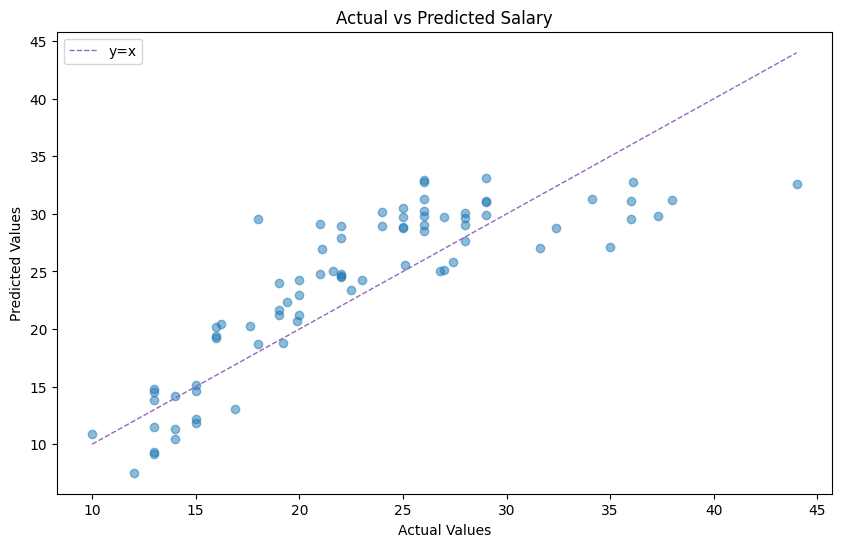

In [86]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.5)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C4", label="y=x")
ax.set_title("Actual vs Predicted Salary")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values")
ax.legend();

In [87]:
# რამდენად მნიშვნელოვანია მახასიათებლები (feature importance)
importance = np.abs(model.coef_).round(2) # y = a_1 x_1 + a_2 x_2 + a_0
feature_names = model.feature_names_in_

# Create DataFrame for better visualization
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
1,acceleration,0.28
0,weight,0.01


In [88]:
def all_metrics(y_true, y_hat):
    mae = mean_absolute_error(y_true, y_hat)
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_hat)
    return mae, mse, rmse, r2

In [89]:
# მეტრიკებით პროგნოზის შეფასება, თუ რამდენად შორსაა ის ნამდვილი მნიშვნელობებისაგან
mae, mse, rmse, r2 = all_metrics(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - miles per gallon
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - miles per gallon²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - miles per gallon
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 3.49
Mean Squared Error (MSE): 17.66
Root Mean Squared Error (RMSE): 4.20
R² Score: 0.65


If our model beats the mean-baseline’s RMSE clearly and the median-baseline’s MAE by 20–30%, that’s a solid improvement.

In [90]:
# Baselines
# - Mean baseline: best constant for MSE/RMSE/R²
base_mean = DummyRegressor(strategy="mean")
base_mean.fit(X_train, y_train)
y_pred_mean = base_mean.predict(X_test)

# - Median baseline: best constant for MAE
base_median = DummyRegressor(strategy="median")
base_median.fit(X_train, y_train)
y_pred_median = base_median.predict(X_test)

m_lin = all_metrics(y_test, y_pred)
m_mean = all_metrics(y_test, y_pred_mean)
m_median = all_metrics(y_test, y_pred_median)

# comparison
out = pd.DataFrame(
    [m_lin, m_mean, m_median],
    columns=["MAE", "MSE", "RMSE", "R2"],
    index=["LinearRegression", "Baseline_mean", "Baseline_median"]
)

print(out.round(3))

                    MAE     MSE   RMSE     R2
LinearRegression  3.489  17.657  4.202  0.654
Baseline_mean     5.881  51.620  7.185 -0.011
Baseline_median   5.828  51.067  7.146 -0.001


### Overfitting & regularisation

როდესაც რეგრესიის ამოცანისთვის დავასკვნით რომ overfitting-ან გვაქვს საქმე
(სატრენინგო მონაცემებზე მოდელი კარგ შედეგებს გვაძლევს, ხოლო სატესტო მონაცემებზე ვერ აკეთებს კარგად განზოგადებას),
შეგვიძლია შემდეგი სტრატეგიები გამოვიყენოთ, იმისათვის რომ ავიცილოთ overfitting-ის პრობლემა.


1. რეგულარიზაციის დამატება (regularisation)

შემდეგი მეთოდები გამოიყენება overfitting-ის დროს:

- Ridge Regression (L2) → ამცირებს კოეფიციენტებს
- Lasso Regression (L1) → იმ კოეფიციენტებს, რომლებიც არ არიან საჭირო, უტოლებს 0-ს.
- ElasticNet → ორივეს კომბინაცია

არეგულირებს მოდელის კომპლექსურობას და თავიდან იცილებს დიდ წონებს.

2. Cross-Validation გაყოფა ერთჯერადი გაყოფის ნაცვლად

- Cross-Validation-ის გამოყენება უზრუნველყოფს, რომ მოდელი მხოლოდ რომელიმე Trainings/Test სიმრავლეზე არ დაკონცენტრირდეს.

3. Feature Selection

- არარელევანტური ან რედუნდანტი მახასიათებლების ჩამოშორება
- Tools: კორელაციის ანალიზი, `SelectKBest`

რაც უფრო ნაკლები არარელევანტური მახასიათებლები გვაქვს, მით ნაკლებია Overfitting-რისკი.

4. Multikollinearity

- როდესაც მახასიათებლები ერთმანეთთან კორელირებენ, შესაძლოა გამოიწვიოს  Overfitting.
- Tools: კორელაციის ანალიზი, Variance Inflation Factor (VIF)

ძლიერად კორელირებული მახასითებლები ჯობია შევაჯამოთ ან მხოლოდ ერთი მათგანი გადავცეთ მოდელს.

5. მონაცემების გაწმენდა

- Outlier-ის ჩამოშორება
- Feature-Scaling

6. მეტი მონაცემების შეგროვება

- უფრო დიდი მონაცემების სიმრავლე = რობასტული მოდელი, ნაკლები შანსი რომ მოხდეს Overfitting.

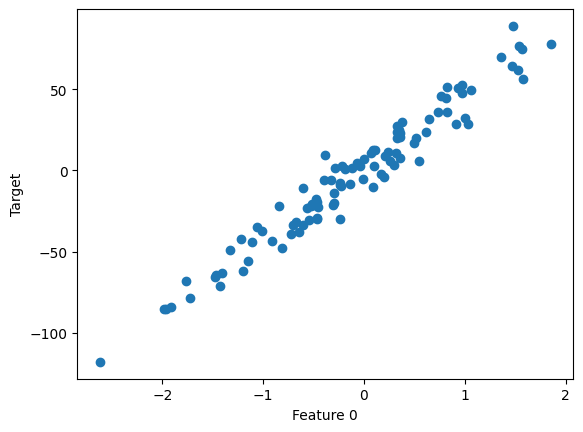

In [92]:
# მონაცემების გენერირება: 100 Samples, 1 Feature + 10 Noise Points
X, y, coef = make_regression(n_samples=100, n_features=1, noise=10, coef=True, random_state=42)

plt.scatter(X[:, 0], y)
plt.xlabel('Feature 0')
plt.ylabel('Target')
plt.show()

In [93]:
# მონაცემების გენერირება: 100 Samples, 20 Features, 5 relevant Features + 10 Noise Points
X, y, coef = make_regression(n_samples=100, n_features=20, n_informative=5, noise=10, coef=True, random_state=42)

# Train/Test გაყოფა
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [94]:
# მოდელი
model = LinearRegression()
model.fit(X_train, y_train)

# პროგნოზი სიმრავლეებზე
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# ევალუაციის მეტრიკები
print("Training MSE:", mean_squared_error(y_train, y_pred_train))
print("Test MSE:", mean_squared_error(y_test, y_pred_test))

Training MSE: 48.500222069834464
Test MSE: 232.82681970613513


### Ridge Regression (L2-Regularisation)

- ამატებს ჯარიმას კოეფიციენტების კვადრატების ჯამის შესაბამისად.
- მიზანი: კოეფიციენტების შემცირება (მაგრამ ნულის ტოლს არ ხდის).
- კარგია, როცა ყველა მახასიათებელი გავლენას ახდენს მოდელზე და როცა Feature-Selection არაა საჭირო.
- ფორმულა:
  $\text{Loss} = \text{MSE} + \alpha \sum w_i^2$,
  
  $MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y_i})^2$

სადაც $w_i$ — მოდელის კოეფიციენტებია (ინტერსეპტის გარეშე).

---

In [97]:
# Ridge (L2)
ridge = Ridge(alpha=50) # უფრო მაღალი ჯარიმა მოგვცემს უფრო პატარა კოეფიციენტებს
ridge.fit(X_train, y_train)

y_pred_train = ridge.predict(X_train)
y_pred_test = ridge.predict(X_test)

print("Ridge MSE:")
print("Training MSE:", mean_squared_error(y_train, y_pred_train))
print("Test MSE:", mean_squared_error(y_test, y_pred_test))

Ridge MSE:
Training MSE: 1424.2412254050446
Test MSE: 1579.956563567935


### Lasso Regression (L1-Regularisation)

- ამატებს ჯარიმას კოეფიციენტების აბსოლიტური მნიშვნელობის ჯამის შესაბამისად.
- მიზანი: ბევრი კოეფიციენტის ნულთან გატოლება -> ავტომატური Feature Selection.
- კარგია, როცა ვვარაუდობთ რომ მხოლოდ რამდენიმე მახასიათებელია მნიშვნელოვანი.
- ფორმულა:
  $\text{Loss} = \text{MSE} + \alpha \sum |w_i|$

---

In [102]:
# Lasso (L1)
lasso = Lasso(alpha=5) # უფრო მაღალი ჯარიმა მოგვცემს მეტ ნულის ტოლ კოეფიციენტებს
lasso.fit(X_train, y_train)

y_pred_train = lasso.predict(X_train)
y_pred_test = lasso.predict(X_test)

print("Lasso MSE:")
print("Training MSE:", mean_squared_error(y_train, y_pred_train))
print("Test MSE:", mean_squared_error(y_test, y_pred_test))

Lasso MSE:
Training MSE: 230.94619848544835
Test MSE: 249.7443208498173


### ElasticNet

$\text{Loss} = \text{MSE} + \alpha \cdot \left( \, \underbrace{(1 - \text{l1\_ratio}) \cdot \sum_{j} w_j^2}_{\text{Ridge (L2)}} \, + \, \underbrace{\text{l1\_ratio} \cdot \sum_{j} |w_j|}_{\text{Lasso (L1)}} \, \right)$

- l1_ratio:
  - $=1$: მხოლოდ Lasso
  - $=0$: მხოლოდ Ridge
  - 0-და და 1-ს შორის: კომბინაცია

მაგალითად, როცა `alpha=1.0` და `l1_ratio=0.5` ვირჩევთ:

$\text{Loss} = \text{MSE} + 0.5 \cdot \sum w_j^2 + 0.5 \cdot \sum |w_j|$



In [103]:
# ElasticNet = Lasso (L1) & Ridge (L2)-ის კომბინაცია
elastic = ElasticNet(alpha=1, l1_ratio=0.5)  # l1_ratio=0.5 => 50% L1, 50% L2
elastic.fit(X_train, y_train)

y_pred_train = elastic.predict(X_train)
y_pred_test = elastic.predict(X_test)

print("ElasticNet MSE:")
print("Training MSE:", mean_squared_error(y_train, y_pred_train))
print("Test MSE:", mean_squared_error(y_test, y_pred_test))

ElasticNet MSE:
Training MSE: 1142.7774999754233
Test MSE: 1314.4902099504013


In [104]:
pd.DataFrame({
    "Linear" : model.coef_.round(2),
    "Ridge" : ridge.coef_.round(2),
    "Lasso" : lasso.coef_.round(2),
    "ElasticNet": elastic.coef_.round(2),
})

,Linear,Ridge,Lasso,ElasticNet
0,8.90,2.34,1.27,2.66
1,-0.69,0.64,0.00,0.17
2,39.19,19.17,31.54,20.88
3,0.49,2.13,0.00,1.69
4,-1.76,0.45,-0.00,0.00
5,0.49,-0.90,-0.00,-0.61
6,10.39,3.18,3.54,3.38
7,-1.11,1.41,-0.00,0.81
8,79.14,44.33,73.10,48.13
9,38.39,28.48,33.97,30.10


In [105]:
print("არანულოვანი კოეფიციენტების რაოდენობა Ridge:", np.sum(ridge.coef_ != 0))
print("არანულოვანი კოეფიციენტების რაოდენობა Lasso:", np.sum(lasso.coef_ != 0))
print("არანულოვანი კოეფიციენტების რაოდენობა ElasticNet:", np.sum(elastic.coef_ != 0))

არანულოვანი კოეფიციენტების რაოდენობა Ridge: 20
არანულოვანი კოეფიციენტების რაოდენობა Lasso: 5
არანულოვანი კოეფიციენტების რაოდენობა ElasticNet: 17


### როდის რომელი მიდგომა გამოვიყენოთ?

| Situation | Ridge | Lasso | ElasticNet |
|----------|-------|-------|-------------|
| ბევრი არარელევანტური მახასიათებელი | - | ✓ | ✓ |
| ბევრი მახასიათებელი, რომლებიც ერთმანეთთან კორელირებენ | ✓ | - | ✓ |
| ყველა მახასიათებელი მნიშვნელოვანია | ✓ | - | - |
| უმნიშვნელო მახასიათებლების ავტომატური ჩამოშორება | - | ✓ | ✓ |
| Feature-Selection და კორელაცია | - | - | ✓ |
---